In [20]:
import pandas as pd
import numpy as np
from pacha.utils import instruments as iutils
from pacha.visualisation import geospatial as gvis
import matplotlib.pyplot as plt
from pacha.utils import file_utils as futils
import os
import re


In [2]:

def read_single_TOA5_csv(file_path: str):
    with open(file_path, "r", encoding="utf-8") as f:
        f.readline()  # Skip line 1 (Metadata)
        header_line = f.readline()  # Grab line 2 (Column Names)
        # Clean the line by stripping quotes and splitting by commas
        column_names = [col.strip('" \n') for col in header_line.split(",")]

    # 2. Parse the rest of the file into a DataFrame
    df = pd.read_csv(
        file_path,
        skiprows=4,  # Skip all 4 TOA5 header lines
        names=column_names,  # Inject the extracted columns
        na_values=['"NAN"', "NAN", "NaN", '"NaN"'],  # Handle logger null values safely
        quotechar='"',
    )

    # 3. Correctly parse the TOA5 TIMESTAMP into datetime
    df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"])

    # Optional: Set the TIMESTAMP as the index for time-series work
    df.set_index("TIMESTAMP", inplace=True)
    return df

In [3]:
dir_path_gauges = '/media/admingosset/T7Shield/data/raw_data/ceara/pcds/pcds_funceme_eto_Dez_min/'
fpaths = futils.get_fpaths_from_dir(dir_path_gauges)

In [15]:
fpaths_dat = [i for i in fpaths if i.endswith('.dat')]
fpath_coords = [i for i in fpaths if 'coordenadas' in i][0]

df_coords = pd.read_csv(fpath_coords)
df_sample_pcd = pd.read_csv(fpaths_dat[0], low_memory=False)

df_coords['name'] = df_coords['PCD nome']
df_coords.rename(columns={'PCD nome': 'id', 'latitude':'lat', 'longitude': 'lon', 'altitude (m)': 'alt'}, inplace=True)

import unicodedata

def normalize(s):
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return s.lower().replace(" ", "_")

df_coords['id'] = [normalize(i) for i in df_coords.id]
df_coords.set_index('id', inplace=True)

print(f'contents of {fpath_coords}')
display(df_coords.head())

print(f'contents of {fpaths_dat[0]}')
display(df_sample_pcd.head())


contents of /media/admingosset/T7Shield/data/raw_data/ceara/pcds/pcds_funceme_eto_Dez_min/coordenadas_pcds.csv


,lat,lon,alt,name
id,,,,
alto_santo,-5.509194,-38.440500,102,Alto Santo
araripe,-7.157427,-40.108592,659,Araripe
baturite,-4.345528,-38.857500,168,Baturité
caninde,-4.621694,-39.392778,280,Canindé
crato,-7.212167,-39.443639,539,Crato


contents of /media/admingosset/T7Shield/data/raw_data/ceara/pcds/pcds_funceme_eto_Dez_min/pcd_eto_alto_santo_Dez_min_15_03_2024.dat


,,,,,,,,,,TOA5,PCD et0 castanhao alto santo,CR1000X,28898,CR1000X.Std.05.01,CPU:Funceme_TX325_PCD23_AltoSanto.cr1x,22121,Dez_min
TIMESTAMP,RECORD,battery_voltage,battery_voltage_Avg,panel_temperature_Avg,AirTC_Avg,RH,SHF_Avg,T108_5cm_Avg,T108_10cm_Avg,T108_30cm_Avg,SlrW_Avg,SlrkJ_Tot,Teros10_Avg,WindSpeed_Avg,WindDir,BP_mbar_Avg,Rain_Tot
TS,RN,Volts,Volts,Deg C,Deg C,%,W/m^2,Deg C,Deg C,Deg C,W/m^2,kJ/m^2,m^3/m^3,m/s,degrees,mbar,mm
NaN,NaN,Smp,Avg,Avg,Avg,Smp,Avg,Avg,Avg,Avg,Avg,Tot,Avg,Avg,Smp,Avg,Tot
2022-06-02 15:40:00,0,13.59,13.59,29.89,NAN,84,7.121,29.47,29.39,29.03,261.9,141.4388,0.293,NAN,67.3,997.5032,0
2022-06-02 15:50:00,1,13.58,13.59,29.78,26.86,85.6,6.934,29.45,29.37,29.04,270.5,162.3117,0.293,3.16,94.9,997.374,0


In [5]:
# TOA5-oriented parsing

sample_fpath = fpaths_dat[0]

# 1. Read just the second line to capture the actual column headers
with open(sample_fpath, "r", encoding="utf-8") as f:
    f.readline()  # Skip line 1 (Metadata)
    header_line = f.readline()  # Grab line 2 (Column Names)
    # Clean the line by stripping quotes and splitting by commas
    column_names = [col.strip('" \n') for col in header_line.split(",")]

# 2. Parse the rest of the file into a DataFrame
df = pd.read_csv(
    sample_fpath,
    skiprows=4,  # Skip all 4 TOA5 header lines
    names=column_names,  # Inject the extracted columns
    na_values=['"NAN"', "NAN", "NaN", '"NaN"'],  # Handle logger null values safely
    quotechar='"',
)

# 3. Correctly parse the TOA5 TIMESTAMP into datetime
df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"])

# Optional: Set the TIMESTAMP as the index for time-series work
df.set_index("TIMESTAMP", inplace=True)
print('correctly read dataframe:')
display(df.head())

# 4 Make this into a function 

# moved to top

# extract station from filename

fname = sample_fpath.split('/')[-1]
print(fname)

# regex to only get in-between "eto_" and "_Dez_min"

fnames = [i.split('/')[-1] for i in fpaths_dat]

stations = [
    m.group(1)
    for f in fnames
    if (m := re.search(r"pcd_eto_(.*?)_Dez_min", f))
]

dates_recoup = [
    m.group(1)
        for f in fnames
        if (m := re.search(r"Dez_min_(.*?).dat", f))
]
# group fpaths by station_name 

unique_stations = set(stations)

fpaths_by_station = {u: [i for i in fpaths_dat if u in i] for u in stations}

correctly read dataframe:


,RECORD,battery_voltage,battery_voltage_Avg,panel_temperature_Avg,AirTC_Avg,RH,SHF_Avg,T108_5cm_Avg,T108_10cm_Avg,T108_30cm_Avg,SlrW_Avg,SlrkJ_Tot,Teros10_Avg,WindSpeed_Avg,WindDir,BP_mbar_Avg,Rain_Tot
TIMESTAMP,,,,,,,,,,,,,,,,,
2022-06-02 15:40:00,0,13.59,13.59,29.89,NaN,84.0,7.121,29.47,29.39,29.03,261.9,141.4388,0.293,NaN,67.3,997.5032,0.0
2022-06-02 15:50:00,1,13.58,13.59,29.78,26.86,85.6,6.934,29.45,29.37,29.04,270.5,162.3117,0.293,3.160,94.9,997.3740,0.0
2022-06-02 16:00:00,2,13.58,13.60,29.61,26.66,85.1,6.911,29.45,29.37,29.05,296.7,178.0407,0.293,3.447,74.5,997.2095,0.0
2022-06-02 16:10:00,3,13.60,13.60,29.74,26.55,83.8,6.386,29.44,29.37,29.06,394.7,236.8320,0.293,3.869,91.2,997.0694,0.0
2022-06-02 16:20:00,4,13.60,13.60,30.01,26.74,81.7,6.193,29.44,29.37,29.08,410.8,246.5069,0.293,3.355,70.6,996.9493,0.0


pcd_eto_alto_santo_Dez_min_15_03_2024.dat


In [6]:
from datetime import datetime as dt

dfs_by_station = {}

for station in unique_stations:
    fpaths_for_station = fpaths_by_station[station]
    
    dates_recoup = [
        m.group(1)
            for f in fpaths_for_station
            if (m := re.search(r"Dez_min_(.*?).dat", f))
    ]
    dates_recoup = [(dt.strptime(i, "%d_%m_%Y")).date() for i in dates_recoup]
    dt_max = np.max(dates_recoup)
    dfs_for_station = [read_single_TOA5_csv(fp) for fp in sorted(fpaths_for_station)]

    if len(dfs_for_station) > 1:
        df_full = pd.concat(dfs_for_station)
        df_full.sort_index(inplace=True)
    else:
        df_full = dfs_for_station[0]
        df_full.sort_index(inplace=True)
    df_full = df_full.loc['2020':str(dt_max)].drop_duplicates()
    dfs_by_station[station] = df_full

In [7]:
field_to_extract = 'Rain_Tot'
dfs_corr = []
for key in dfs_by_station.keys():
    df = dfs_by_station[key]
    df_rain = df.loc[:, field_to_extract].to_frame()
    df_rain.rename(columns={field_to_extract: key}, inplace=True)
    df_rain = df_rain[~df_rain.index.duplicated(keep='first')]
    dfs_corr.append(df_rain)

In [26]:
df_complete_rain = pd.concat(dfs_corr, axis=1)
df_complete_rain = df_complete_rain.loc[:, df_coords.index]
df_complete_rain.index.name = 'time'

In [27]:
display(df_complete_rain.head())
display(df_coords.head())

id,alto_santo,araripe,baturite,caninde,crato,ibaretama,icapui,iguatu,itatira,jaguaribara,limoeiro_do_norte,missao_velha,morada_nova,pacajus,poranga,quixere,russas,santa_quiteria,sao_benedito,varjota
time,,,,,,,,,,,,,,,,,,,,
2022-04-07 16:10:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-07 16:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-07 16:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-07 16:40:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-07 16:50:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,lat,lon,alt,name
id,,,,
alto_santo,-5.509194,-38.440500,102,Alto Santo
araripe,-7.157427,-40.108592,659,Araripe
baturite,-4.345528,-38.857500,168,Baturité
caninde,-4.621694,-39.392778,280,Canindé
crato,-7.212167,-39.443639,539,Crato


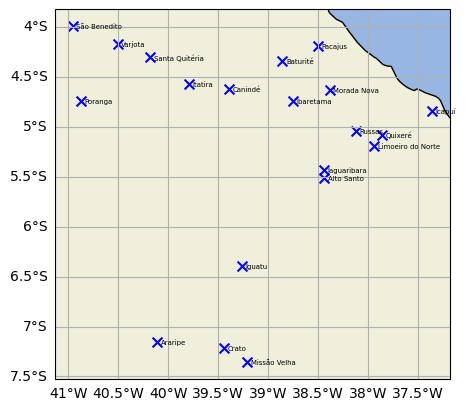

In [21]:
gvis.plot_simple_map()
ax = plt.gca()
gvis.plot_gauge_network(df_coords, display_names=True)

In [28]:
outdir = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/'

data_fname = 'gauges_10min_utc.csv'
metadata_fname = 'gauges_10min_utc_metadata.csv'

df_complete_rain.to_csv(f'{outdir}{data_fname}')
df_coords.to_csv(f'{outdir}{metadata_fname}')